# How many parking violations should we expect?

This example compares Poisson and negative binomial regression to see which model assigns more probability to held-out counts when the data are overdispersed.

The demonstration uses 180 fictional countries, each observed in two periods. The counts were simulated from a negative binomial distribution. The example grew out of a class on count models and was inspired by Fisman and Miguel’s study of diplomatic parking violations (DOI `10.1086/527495`).

Open this notebook in VS Code with the Jupyter extension, select the virtual environment described in the README, and run all cells.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import nbinom, poisson
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance
from sklearn.model_selection import GroupShuffleSplit

In [2]:
from pathlib import Path

csv = Path("data/training.csv")
data = pd.read_csv(csv)

## Splitting by country

The split keeps both observations from each country together. The test set measures performance on countries held out from fitting. Both models use the same predictors.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_indices, test_indices = next(splitter.split(data, groups=data["code"]))
training, test = data.iloc[train_indices], data.iloc[test_indices]
assert set(training["code"]).isdisjoint(test["code"])

formula = "violations ~ staff + C(post) + corruption"
poisson_model = sm.Poisson.from_formula(formula, training).fit(disp=False)
nb_model = sm.NegativeBinomial.from_formula(formula, training).fit(
    method="bfgs", maxiter=300, disp=False
)

training_mean = poisson_model.predict(training)
dispersion = (((training["violations"] - training_mean) ** 2 / training_mean).sum()
             / poisson_model.df_resid)
alpha = nb_model.params["alpha"]
print(f"Training countries: {training['code'].nunique()} | Test countries: {test['code'].nunique()}")
print(f"Poisson Pearson dispersion on training data: {dispersion:.2f}")
print(f"Estimated negative binomial alpha: {alpha:.3f}")

Training countries: 135 | Test countries: 45
Poisson Pearson dispersion on training data: 5.17
Estimated negative binomial alpha: 0.928


## Held-out evaluation

In the Poisson model, conditional variance equals the estimated mean. In the NB2 model, it is μ + αμ². Pearson dispersion above 1 is a descriptive sign of overdispersion in the Poisson fit. MAE and mean Poisson deviance evaluate the predicted means. Mean negative log-likelihood measures how much probability each model assigns to the observed counts. Lower values are better for all three metrics.

                    MAE  Poisson deviance  Mean negative log-likelihood
Poisson            5.12              6.97                          4.62
Negative binomial  5.10              6.66                          2.45


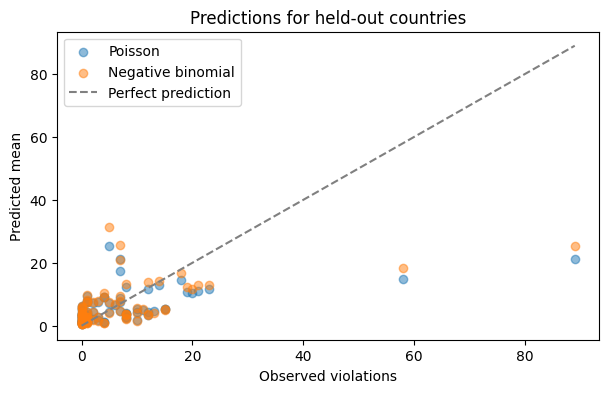

In [4]:
observed = test["violations"]
poisson_mean = poisson_model.predict(test)
nb_mean = nb_model.predict(test)
nb_size = 1 / alpha
nb_probability = nb_size / (nb_size + nb_mean)

results = pd.DataFrame({
    "MAE": [mean_absolute_error(observed, m) for m in (poisson_mean, nb_mean)],
    "Poisson deviance": [mean_poisson_deviance(observed, m) for m in (poisson_mean, nb_mean)],
    "Mean negative log-likelihood": [
        -poisson.logpmf(observed, poisson_mean).mean(),
        -nbinom.logpmf(observed, nb_size, nb_probability).mean(),
    ],
}, index=["Poisson", "Negative binomial"])
print(results.round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(observed, poisson_mean, alpha=0.5, label="Poisson")
ax.scatter(observed, nb_mean, alpha=0.5, label="Negative binomial")
upper_limit = max(observed.max(), poisson_mean.max(), nb_mean.max())
ax.plot([0, upper_limit], [0, upper_limit], "--", color="gray", label="Perfect prediction")
ax.set(xlabel="Observed violations", ylabel="Predicted mean", title="Predictions for held-out countries")
ax.legend()
plt.show()

## Results

Mean negative log-likelihood was 2.45 for negative binomial regression and 4.62 for Poisson regression. MAE was similar at 5.10 and 5.12 violations, respectively. The better likelihood for the negative binomial model is consistent with the distribution used to simulate the counts.